# Klasifikasi Citra Pakaian dengan CNN Dasar dari Scratch (TensorFlow)

**Tugas 1 (UTS):** model dibangun **dari awal** (tanpa *transfer learning* dan tanpa bobot terlatih) menggunakan **Convolutional Neural Network (CNN) dasar**, dengan **TensorFlow/Keras** untuk operasi tensor dan **`tf.data`** untuk *input pipeline*.

**Data:** *Fashion Product Images (Small)* dari Kaggle (foto produk berwarna 80 x 60 piksel + `styles.csv`). Label: `articleType` (Tshirts, Shirts, Jeans, Dresses, dst.), hanya kategori `Apparel`.

**Alur:** unduh data -> bersihkan dan seimbangkan -> split train/val/test -> `tf.data` pipeline -> bangun CNN -> latih (Adam + LR scheduling + early stopping) -> evaluasi -> analisis kesalahan -> simpan model.

### Pemetaan kebutuhan RTM ke kode

| Kebutuhan | Di mana diterapkan |
|---|---|
| TensorFlow untuk operasi tensor | Seluruh model dan pelatihan (`tf.keras`), augmentasi (`tf.image`) |
| `tf.data` untuk input pipeline | Bagian 5 (`tf.data.Dataset`, `map`, `shuffle`, `batch`, `prefetch`) |
| Model dari scratch (bukan transfer learning) | Bagian 6 (CNN dasar, bobot diinisialisasi acak) |
| Loss function | `CategoricalCrossentropy` dengan *label smoothing* (Bagian 7) |
| Dropout | Setelah tiap blok konvolusi dan sebelum lapisan output (Bagian 6) |
| Batch normalization | Setelah tiap `Conv2D` dan `Dense` (Bagian 6) |
| Optimizer Adam/RMSProp | `Adam` (bisa diganti `RMSprop` lewat `CONFIG["optimizer"]`) (Bagian 7) |
| Learning rate scheduling | `ReduceLROnPlateau` (Bagian 7) |
| Early stopping | `EarlyStopping(restore_best_weights=True)` (Bagian 7) |

**Cara menjalankan:** Google Colab (Runtime > Change runtime type > GPU) atau Kaggle Notebook. `kagglehub` dapat meminta login Kaggle saat mengunduh.

## 1. Import library dan konfigurasi

In [1]:
!pip install -q kagglehub

In [2]:
import os, random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support)

sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
CONFIG = {
    "dataset": "paramaggarwal/fashion-product-images-small",  # slug dataset Kaggle
    "master_category": "Apparel",   # hanya pakaian; isi None untuk semua kategori
    "min_per_class": 400,           # buang kelas dengan gambar kurang dari ini
    "max_per_class": 2000,          # batasi kelas besar agar tidak terlalu timpang
    "img_h": 80, "img_w": 60,       # ukuran asli gambar (tinggi x lebar), tanpa upscale
    "seed": 42,
    "batch_size": 64,
    "epochs": 60,                   # batas maksimal; early stopping biasanya berhenti lebih awal
    "optimizer": "adam",            # "adam" atau "rmsprop"
    "lr": 1e-3,
    "label_smoothing": 0.1,
    "conv_dropout": 0.25,           # dropout setelah blok konvolusi
    "dense_dropout": 0.5,           # dropout sebelum output
    "filters": [32, 64, 128],       # jumlah filter tiap blok konvolusi
    "dense_units": 256,
    "lr_factor": 0.5,               # LR dikali 0.5 bila val_loss stagnan
    "lr_patience": 3,
    "min_lr": 1e-6,
    "es_patience": 8,               # early stopping
}

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)   # python, numpy, dan tensorflow sekaligus

set_seed(CONFIG["seed"])

## 2. Mengunduh dan memeriksa data

Sel di bawah mengunduh dataset lalu **mencetak struktur foldernya**, supaya mudah dicek jika ada perbedaan nama file/folder.

In [4]:
import kagglehub

root = kagglehub.dataset_download(CONFIG["dataset"])
print("Lokasi data:", root)

for dirpath, dirnames, files in os.walk(root):
    depth = dirpath[len(root):].count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(dirpath) + "/", f"({len(files)} file)")

styles_path, images_dir = None, None
for dirpath, dirnames, files in os.walk(root):
    if "styles.csv" in files and styles_path is None:
        styles_path = os.path.join(dirpath, "styles.csv")
    if os.path.basename(dirpath) == "images" and images_dir is None:
        images_dir = dirpath

assert styles_path is not None, "styles.csv tidak ditemukan - cek struktur folder di atas"
assert images_dir is not None, "folder images tidak ditemukan - cek struktur folder di atas"
print("styles.csv :", styles_path)
print("folder gambar:", images_dir)

Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
Lokasi data: /kaggle/input/fashion-product-images-small
fashion-product-images-small/ (1 file)
  myntradataset/ (1 file)
    images/ (44441 file)
  images/ (44441 file)
styles.csv : /kaggle/input/fashion-product-images-small/styles.csv
folder gambar: /kaggle/input/fashion-product-images-small/myntradataset/images


In [5]:
# Beberapa baris styles.csv rusak (kolom berlebih) -> dilewati
df = pd.read_csv(styles_path, on_bad_lines="skip")
print("Jumlah baris:", len(df))
display(df.head())

# Pastikan file gambar benar-benar ada
existing = set(os.listdir(images_dir))
df["filename"] = df["id"].astype(str) + ".jpg"
df = df[df["filename"].isin(existing)].copy()
df["path"] = df["filename"].map(lambda f: os.path.join(images_dir, f))
print("Baris dengan gambar tersedia:", len(df))

Jumlah baris: 44424


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


Baris dengan gambar tersedia: 44419


## 3. Pembersihan dan penyeimbangan kelas

- Hanya kategori utama yang dipilih (default: `Apparel`).
- Kelas dengan gambar terlalu sedikit dibuang.
- Kelas yang sangat besar dibatasi jumlahnya (*undersampling*) agar model tidak bias ke kelas dominan.

In [6]:
if CONFIG["master_category"]:
    df = df[df["masterCategory"] == CONFIG["master_category"]]
df = df.dropna(subset=["articleType"])

counts = df["articleType"].value_counts()
keep = counts[counts >= CONFIG["min_per_class"]].index
df = df[df["articleType"].isin(keep)]

df = df.sample(frac=1, random_state=CONFIG["seed"])                      # acak
df = df.groupby("articleType").head(CONFIG["max_per_class"]).reset_index(drop=True)

CLASS_NAMES = sorted(df["articleType"].unique())
class2idx = {c: i for i, c in enumerate(CLASS_NAMES)}
df["label"] = df["articleType"].map(class2idx)
NUM_CLASSES = len(CLASS_NAMES)

print("Jumlah kelas :", NUM_CLASSES)
print("Total gambar :", len(df))
print(CLASS_NAMES)

Jumlah kelas : 11
Total gambar : 11508
['Bra', 'Briefs', 'Dresses', 'Jeans', 'Kurtas', 'Sarees', 'Shirts', 'Shorts', 'Tops', 'Trousers', 'Tshirts']


## 4. Eksplorasi data (EDA)

Jumlah gambar per kelas:
articleType
Tshirts     2000
Shirts      2000
Kurtas      1844
Tops        1762
Briefs       849
Jeans        608
Shorts       547
Trousers     530
Bra          477
Dresses      464
Sarees       427
Name: count, dtype: int64
------------------------------


/tmp/ipykernel_1366/3849711563.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="articleType", order=order, palette="viridis")


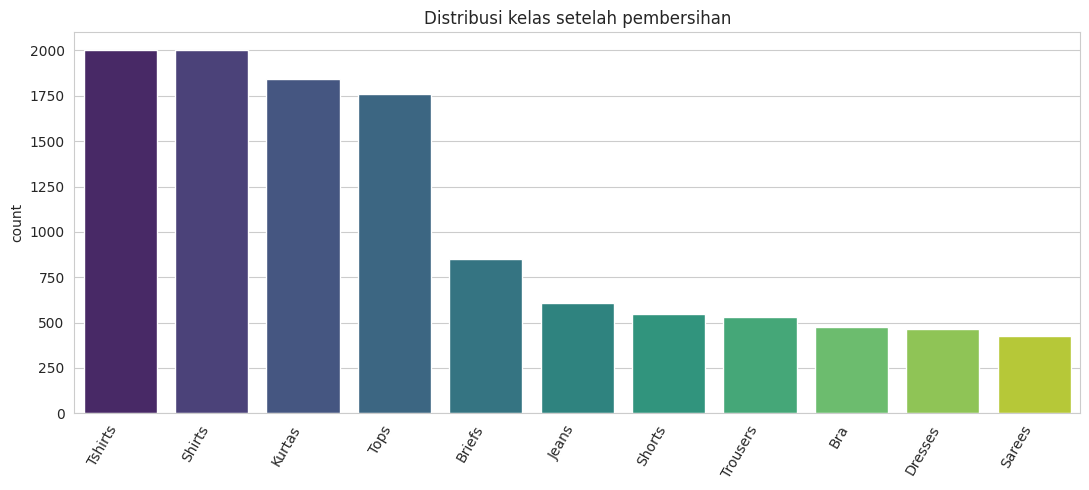

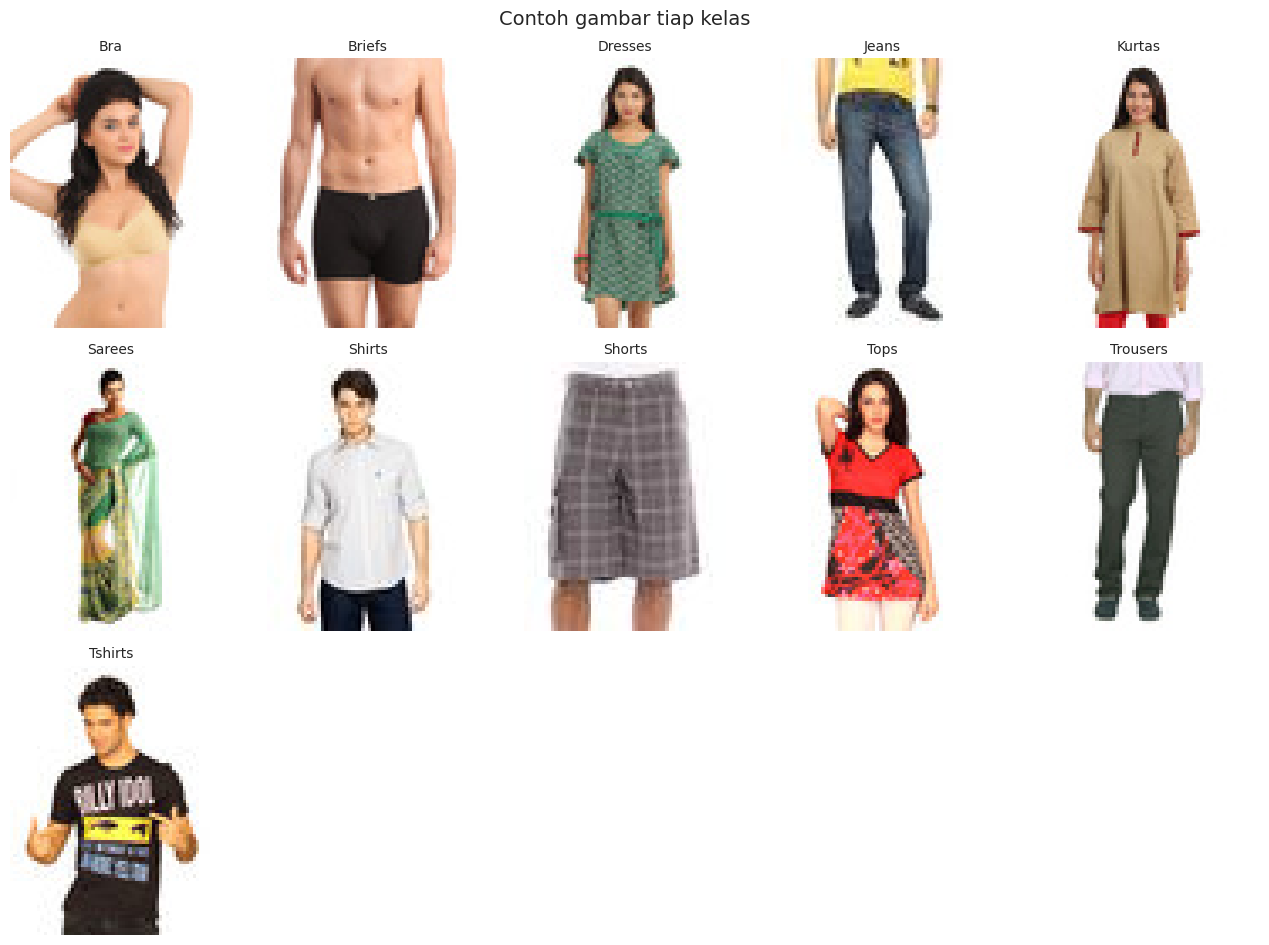

In [7]:
# Print jumlah masing-masing kelas dalam bentuk teks
print("Jumlah gambar per kelas:")
print(df["articleType"].value_counts())
print("-" * 30)

# --- Grafik Bar Chart ---
plt.figure(figsize=(11, 5))
order = df["articleType"].value_counts().index
sns.countplot(data=df, x="articleType", order=order, palette="viridis")
plt.xticks(rotation=60, ha="right"); plt.title("Distribusi kelas setelah pembersihan")
plt.xlabel(""); plt.tight_layout(); plt.show()

# --- Contoh gambar: 1 per kelas ---
from PIL import Image
n_show = min(NUM_CLASSES, 20)
cols = 5; rows = int(np.ceil(n_show / cols))
fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 3.2 * rows))
for ax in np.array(axes).ravel(): ax.axis("off")
for ax, c in zip(np.array(axes).ravel(), CLASS_NAMES[:n_show]):
    p = df[df["articleType"] == c].iloc[0]["path"]
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(c, fontsize=10)
plt.suptitle("Contoh gambar tiap kelas", fontsize=14); plt.tight_layout(); plt.show()

## 5. Split data dan input pipeline `tf.data`

Pembagian **70% train / 15% validasi / 15% test** (*stratified*). Pipeline `tf.data`:

`path + label -> baca file -> decode JPEG -> resize -> skala 0-1 -> (train saja: shuffle + augmentasi) -> one-hot -> batch -> prefetch`

Augmentasi hanya dipakai pada data **train**. Operasi gambar memakai `tf.image`; rotasi memakai layer Keras `RandomRotation` yang dijalankan di dalam pipeline `tf.data` (pada level *batch*).

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=CONFIG["seed"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=CONFIG["seed"])
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

H, W = CONFIG["img_h"], CONFIG["img_w"]
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)                 # pastikan 3 kanal RGB
    img = tf.image.resize(img, (H, W))                       # ukuran seragam
    img = tf.cast(img, tf.float32) / 255.0                   # skala piksel 0-1
    return img, label

def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.image.random_saturation(img, 0.8, 1.2)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

rotate = layers.RandomRotation(10 / 360, fill_mode="nearest")   # rotasi hingga 10 derajat

def make_ds(frame, training):
    paths = frame["path"].tolist()
    labels = frame["label"].astype("int32").tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=CONFIG["seed"], reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(CONFIG["batch_size"])
    if training:
        ds = ds.map(lambda x, y: (rotate(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df, training=False)
test_ds  = make_ds(test_df, training=False)      # tanpa shuffle agar urutan prediksi = urutan test_df

xb, yb = next(iter(train_ds))
print("Bentuk batch gambar:", xb.shape, "| label one-hot:", yb.shape)

Train: 8055 | Val: 1726 | Test: 1727
Bentuk batch gambar: (64, 80, 60, 3) | label one-hot: (64, 11)


## 6. Arsitektur CNN dasar (dari scratch)

Model dibangun dari awal dengan bobot yang diinisialisasi acak (tidak ada bobot terlatih). Struktur:

`Input -> [Conv -> BatchNorm -> ReLU] x2 -> MaxPool -> Dropout` (diulang 3 blok, filter 32 -> 64 -> 128) `-> GlobalAveragePooling -> Dense -> BatchNorm -> ReLU -> Dropout -> Dense(softmax)`

- **Batch normalization** menstabilkan dan mempercepat pelatihan.
- **Dropout** mengurangi *overfitting*.
- `use_bias=False` pada Conv/Dense sebelum BatchNorm karena BatchNorm sudah punya parameter geser (*beta*).

In [9]:
def build_cnn(n_classes, filters, dense_units, conv_dropout, dense_dropout):
    inputs = keras.Input(shape=(H, W, 3))
    x = inputs
    for f in filters:
        for _ in range(2):                                   # dua konvolusi per blok
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(conv_dropout)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(dense_dropout)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_scratch")

model = build_cnn(NUM_CLASSES, CONFIG["filters"], CONFIG["dense_units"], CONFIG["conv_dropout"], CONFIG["dense_dropout"])
model.summary()
print("Total parameter:", f"{model.count_params():,}")

Model: "cnn_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 80, 60, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 80, 60, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 80, 60, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 80, 60, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 60, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 60, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 80, 60, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 40, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 40, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 30, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 30, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 40, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 40, 30, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 40, 30, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 40, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 20, 15, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 20, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 20, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 20, 15, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 20, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 324,971 (1.24 MB)

 Trainable params: 323,563 (1.23 MB)

 Non-trainable params: 1,408 (5.50 KB)

Total parameter: 324,971


## 7. Training: Adam + learning rate scheduling + early stopping

- **Loss:** *categorical cross-entropy* dengan *label smoothing* (target dilunakkan agar model tidak terlalu yakin).
- **Optimizer:** Adam (atau RMSprop, atur di `CONFIG["optimizer"]`).
- **Learning rate scheduling:** `ReduceLROnPlateau` menurunkan LR (dikali 0,5) saat `val_loss` stagnan.
- **Early stopping:** berhenti bila `val_loss` tidak membaik selama `es_patience` epoch dan mengembalikan bobot terbaik.

In [10]:
def make_optimizer():
    name = CONFIG["optimizer"].lower()
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=CONFIG["lr"])
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=CONFIG["lr"])
    raise ValueError("optimizer harus 'adam' atau 'rmsprop'")

model.compile(
    optimizer=make_optimizer(),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=CONFIG["label_smoothing"]),
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=CONFIG["lr_factor"],
                                      patience=CONFIG["lr_patience"], min_lr=CONFIG["min_lr"], verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["es_patience"],
                                  restore_best_weights=True, verbose=1),
]

set_seed(CONFIG["seed"])
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=CONFIG["epochs"], callbacks=callbacks, verbose=2)
train_time = time.time() - t0
print(f"Waktu training: {train_time / 60:.1f} menit | epoch berjalan: {len(history.history['loss'])}")

Epoch 1/60
126/126 - 71s - 564ms/step - accuracy: 0.4133 - loss: 1.9155 - val_accuracy: 0.1738 - val_loss: 2.4776 - learning_rate: 0.0010
Epoch 2/60
126/126 - 8s - 61ms/step - accuracy: 0.6437 - loss: 1.3601 - val_accuracy: 0.2926 - val_loss: 2.3704 - learning_rate: 0.0010
Epoch 3/60
126/126 - 8s - 65ms/step - accuracy: 0.7313 - loss: 1.1809 - val_accuracy: 0.3343 - val_loss: 2.0476 - learning_rate: 0.0010
Epoch 4/60
126/126 - 7s - 58ms/step - accuracy: 0.7723 - loss: 1.0993 - val_accuracy: 0.4867 - val_loss: 1.7726 - learning_rate: 0.0010
Epoch 5/60
126/126 - 8s - 65ms/step - accuracy: 0.7917 - loss: 1.0504 - val_accuracy: 0.3059 - val_loss: 2.5172 - learning_rate: 0.0010
Epoch 6/60
126/126 - 8s - 60ms/step - accuracy: 0.8107 - loss: 1.0059 - val_accuracy: 0.2804 - val_loss: 2.3653 - learning_rate: 0.0010
Epoch 7/60

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
126/126 - 8s - 64ms/step - accuracy: 0.8235 - loss: 0.9801 - val_accuracy: 0.2097 - val_loss: 

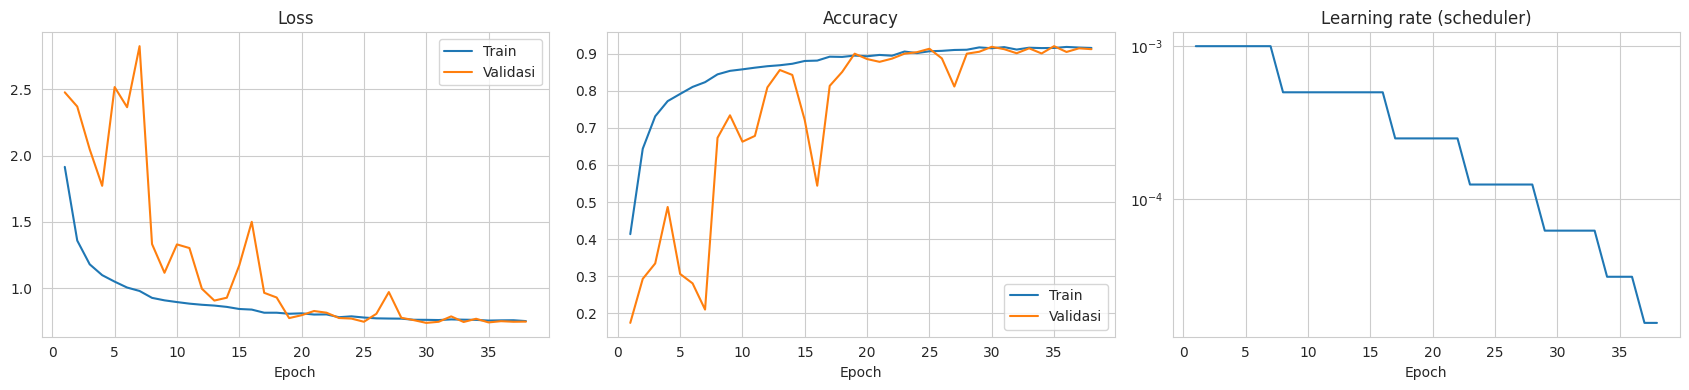

In [11]:
h = history.history
ep = range(1, len(h["loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(ep, h["loss"], label="Train"); ax[0].plot(ep, h["val_loss"], label="Validasi"); ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(ep, h["accuracy"], label="Train"); ax[1].plot(ep, h["val_accuracy"], label="Validasi"); ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
if "learning_rate" in h:
    ax[2].plot(ep, h["learning_rate"]); ax[2].set_yscale("log"); ax[2].set_title("Learning rate (scheduler)"); ax[2].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

## 8. Evaluasi pada data test

Metrik: accuracy, precision, recall, F1 (macro dan weighted), classification report per kelas, dan confusion matrix. Karena kelas tidak sepenuhnya seimbang, **macro F1** penting dilaporkan.

In [12]:
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
y_true = test_df["label"].to_numpy()          # urutan sama karena test_ds tidak di-shuffle

acc = accuracy_score(y_true, y_pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

summary = pd.DataFrame({
    "Accuracy": [acc],
    "Precision (macro)": [p_m], "Recall (macro)": [r_m], "F1 (macro)": [f_m],
    "Precision (weighted)": [p_w], "Recall (weighted)": [r_w], "F1 (weighted)": [f_w],
}, index=["CNN scratch"])
display(summary.round(4))

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
CNN scratch,0.9184,0.9313,0.9216,0.9246,0.9193,0.9184,0.9178


              precision    recall  f1-score   support

         Bra     1.0000    0.9859    0.9929        71
      Briefs     1.0000    0.9766    0.9881       128
     Dresses     0.8594    0.7971    0.8271        69
       Jeans     0.8491    0.9783    0.9091        92
      Kurtas     0.9439    0.9711    0.9573       277
      Sarees     0.9846    1.0000    0.9922        64
      Shirts     0.9357    0.9700    0.9525       300
      Shorts     0.9412    0.9756    0.9581        82
        Tops     0.8377    0.8377    0.8377       265
    Trousers     1.0000    0.7848    0.8794        79
     Tshirts     0.8927    0.8600    0.8761       300

    accuracy                         0.9184      1727
   macro avg     0.9313    0.9216    0.9246      1727
weighted avg     0.9193    0.9184    0.9178      1727



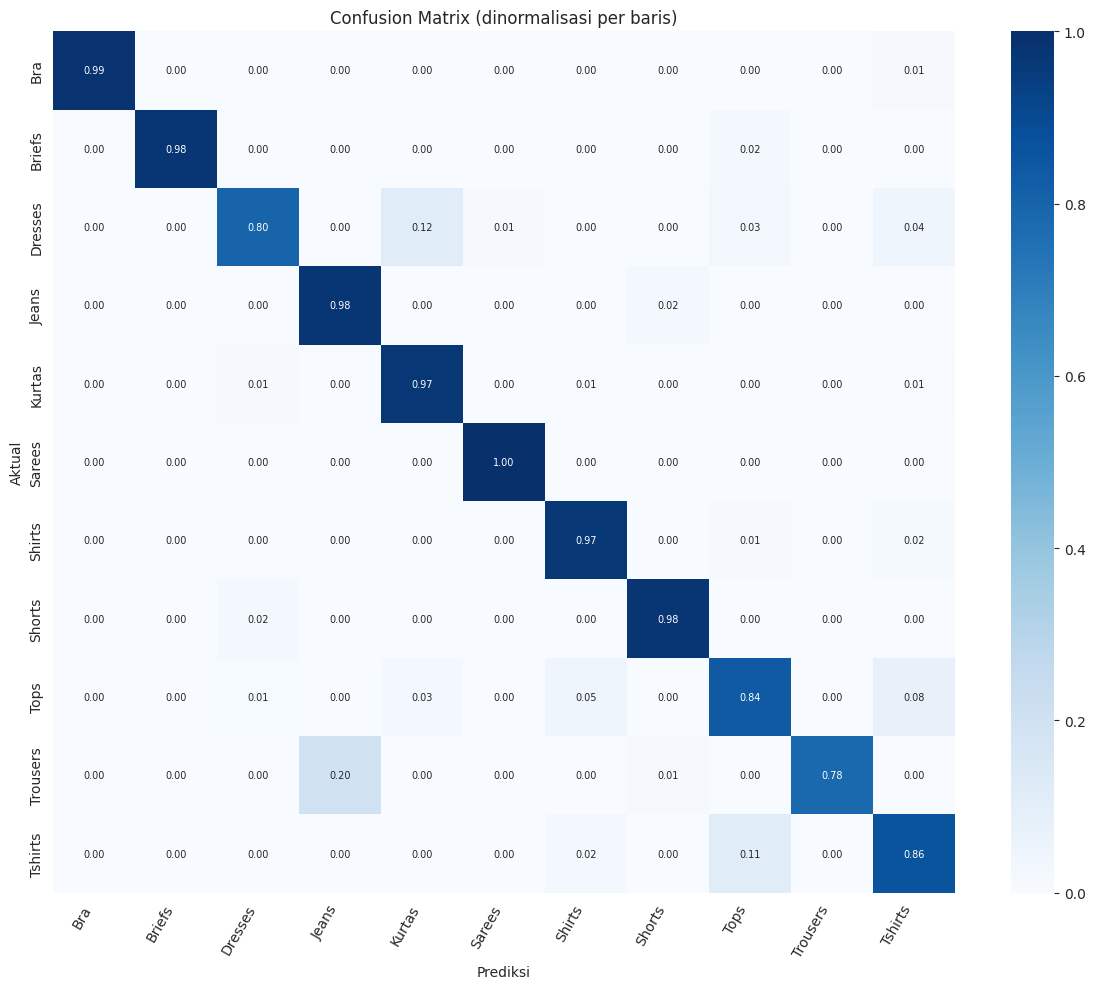

In [13]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            annot_kws={"size": 7})
plt.title("Confusion Matrix (dinormalisasi per baris)")
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.show()

## 9. Analisis kesalahan

Pasangan kelas yang paling sering tertukar dan contoh gambar yang salah diprediksi. Bagian ini berguna untuk pembahasan.

,Kelas aktual,Diprediksi sebagai,Jumlah
0,Tshirts,Tops,34
1,Tops,Tshirts,20
2,Trousers,Jeans,16
3,Tops,Shirts,12
4,Dresses,Kurtas,8
5,Tops,Kurtas,7
6,Tshirts,Shirts,6
7,Shirts,Tshirts,5
8,Kurtas,Dresses,4
9,Shirts,Tops,4


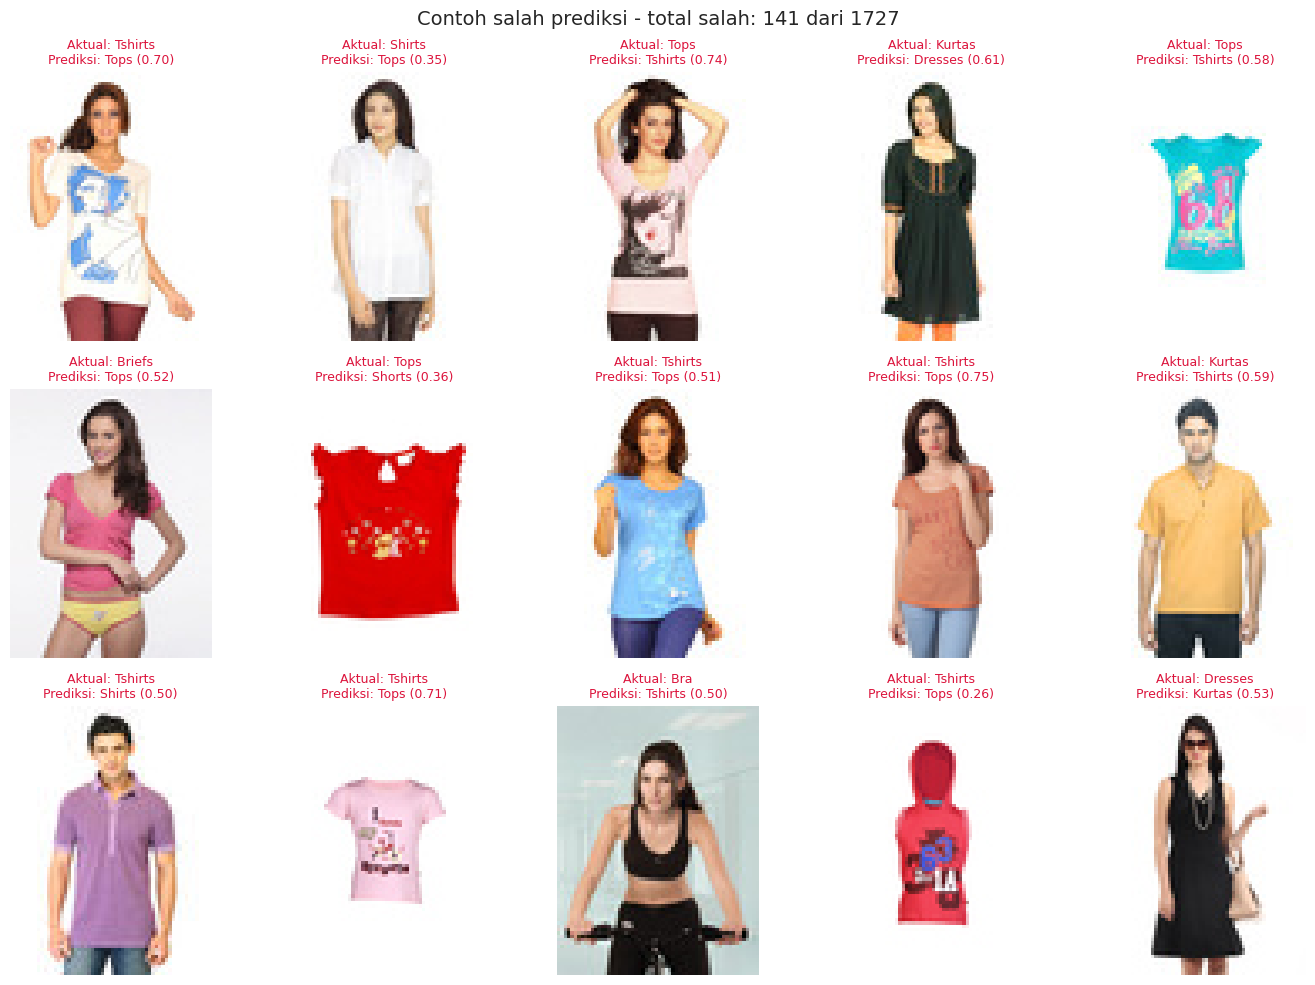

In [14]:
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm_off[i, j]))
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0]
top_pairs = sorted(pairs, key=lambda t: -t[2])[:10]
display(pd.DataFrame(top_pairs, columns=["Kelas aktual", "Diprediksi sebagai", "Jumlah"]))

wrong = np.where(y_pred != y_true)[0]
rng = np.random.RandomState(CONFIG["seed"])
sample = rng.choice(wrong, size=min(15, len(wrong)), replace=False) if len(wrong) else []
test_paths = test_df["path"].tolist()

fig, axes = plt.subplots(3, 5, figsize=(14, 10))
for ax in axes.ravel(): ax.axis("off")
for ax, i in zip(axes.ravel(), sample):
    ax.imshow(Image.open(test_paths[i]).convert("RGB"))
    ax.set_title(f"Aktual: {CLASS_NAMES[y_true[i]]}\nPrediksi: {CLASS_NAMES[y_pred[i]]} "
                 f"({y_prob[i, y_pred[i]]:.2f})", fontsize=9, color="crimson")
plt.suptitle(f"Contoh salah prediksi - total salah: {len(wrong)} dari {len(y_true)}", fontsize=14)
plt.tight_layout(); plt.show()

## 10. Simpan model dan hasil

In [15]:
os.makedirs("outputs", exist_ok=True)
model.save("outputs/cnn_scratch_pakaian.keras")
with open("outputs/class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)
summary.to_csv("outputs/ringkasan_hasil.csv")
pd.DataFrame(classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T \
    .to_csv("outputs/classification_report.csv")
hist_out = {k: [float(v) for v in vals] for k, vals in history.history.items()}
hist_out["train_time_s"] = train_time
with open("outputs/history.json", "w") as f:
    json.dump(hist_out, f)
print("Tersimpan di folder outputs/")

Tersimpan di folder outputs/


## 11. Ide pengembangan (opsional)

- **Eksperimen optimizer:** bandingkan `adam` dan `rmsprop` (ubah `CONFIG["optimizer"]`), laporkan hasil keduanya.
- **Ablation:** dengan vs tanpa BatchNorm, dengan vs tanpa Dropout, dengan vs tanpa augmentasi (menunjukkan peran tiap teknik optimasi).
- **Variasi hyperparameter:** learning rate awal, jumlah filter, besar dropout, batch size.
- **Multi-seed:** ulangi 3-5 kali dengan seed berbeda, laporkan rata-rata dan simpangan baku.

## Sitasi dataset

Aggarwal, P. (2019). *Fashion Product Images Dataset* [Dataset]. Kaggle. https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-dataset
(periksa kembali format sitasi di halaman dataset dan sesuaikan dengan gaya penulisan Anda).

## 12. Dasbor interaktif (User Interface)

Bagian ini menambahkan **dasbor interaktif** di atas model yang sudah dilatih. **Jalankan Bagian 1 sampai 8 terlebih dahulu**, karena dasbor memakai `model`, `history`, `y_true`, `y_pred`, `y_prob`, dan `test_df`.

| Tab | Isi |
|---|---|
| 📊 Ringkasan | Kurva loss/accuracy/learning rate dan distribusi kelas |
| 🎯 Performa Kelas | Precision, recall, F1 per kelas (bisa diurutkan) |
| 🧩 Confusion Matrix | Heatmap (normalisasi atau jumlah) |
| 🖼️ Galeri Prediksi | Telusuri gambar test, filter per kelas dan benar/salah |
| 🔍 Uji Gambar | Unggah foto sendiri, lihat 5 prediksi teratas |
| ⚠️ Analisis Kesalahan | Pasangan kelas yang sering tertukar dan sebaran keyakinan model |
| ⚙️ Konfigurasi | `CONFIG` dan ringkasan arsitektur model |

Teknologi: `ipywidgets` (komponen UI) dan `matplotlib` (grafik dikirim sebagai gambar PNG, sehingga tampil di Colab, Kaggle, Jupyter, maupun VS Code).

In [16]:
!pip install -q ipywidgets


### 12.1 Persiapan data dasbor

In [17]:
import io, base64, html
from PIL import Image
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# ---------- tema ----------
C = dict(primary="#4f46e5", violet="#7c3aed", cyan="#06b6d4", good="#10b981",
         bad="#ef4444", warn="#f59e0b", ink="#0f172a", muted="#64748b")

plt.rcParams.update({
    "font.family": "DejaVu Sans", "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#cbd5e1", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e2e8f0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "text.color": C["ink"], "axes.labelcolor": C["ink"], "xtick.color": C["muted"], "ytick.color": C["muted"],
    "legend.frameon": False,
})

def fig_html(fig, dpi=110):
    """Ubah figure Matplotlib menjadi <img> (PNG base64) agar tampil di widget HTML di semua jenis notebook."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    b64 = base64.b64encode(buf.getvalue()).decode()
    return ('<img src="data:image/png;base64,' + b64 + '" style="max-width:100%;background:#fff;border-radius:12px;'
            'box-shadow:0 2px 10px rgba(15,23,42,.10);margin:0 0 14px 0;display:block">')

# ---------- data turunan dari hasil Bagian 7-9 ----------
cidx = {c: i for i, c in enumerate(CLASS_NAMES)}
hist = history.history
epochs_run = len(hist["loss"])
best_epoch = int(np.argmin(hist["val_loss"])) + 1
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
rep = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
rep_df = pd.DataFrame({c: rep[c] for c in CLASS_NAMES}).T.rename(
    columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1", "support": "Support"})
conf_max = y_prob.max(axis=1)
is_ok = (y_true == y_pred)
test_paths = test_df["path"].tolist()
n_params = model.count_params()

def file_b64(path):
    with open(path, "rb") as f:
        return "data:image/jpeg;base64," + base64.b64encode(f.read()).decode()

def pil_b64(img):
    buf = io.BytesIO(); img.save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

print("Data dasbor siap:", NUM_CLASSES, "kelas |", len(y_true), "gambar uji |", int((~is_ok).sum()), "salah prediksi")


Data dasbor siap: 11 kelas | 1727 gambar uji | 141 salah prediksi


### 12.2 Header dan kartu metrik

In [18]:
CSS = """
<style>
.hdr{background:linear-gradient(135deg,#4f46e5,#7c3aed 60%,#06b6d4);color:#fff;padding:22px 26px;
     border-radius:16px;box-shadow:0 8px 24px rgba(79,70,229,.25);font-family:Inter,Segoe UI,Arial,sans-serif}
.hdr-t{font-size:26px;font-weight:700;letter-spacing:.2px}
.hdr-s{opacity:.92;margin-top:4px;font-size:13.5px}
.kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(130px,1fr));gap:12px;margin:14px 0;
      font-family:Inter,Segoe UI,Arial,sans-serif}
.kpi{background:#fff;border-radius:14px;padding:14px 16px;box-shadow:0 2px 10px rgba(15,23,42,.10);color:#0f172a}
.kpi-l{font-size:11px;text-transform:uppercase;letter-spacing:.6px;color:#64748b;font-weight:600}
.kpi-v{font-size:26px;font-weight:700;margin-top:4px}
.kpi-s{font-size:11.5px;color:#64748b;margin-top:2px}
.gal{display:grid;grid-template-columns:repeat(auto-fill,minmax(150px,1fr));gap:12px;
     font-family:Inter,Segoe UI,Arial,sans-serif}
.gc{background:#fff;border-radius:12px;padding:8px;border:2px solid;color:#0f172a;text-align:center;
    box-shadow:0 2px 8px rgba(15,23,42,.08)}
.gc img{width:100%;border-radius:8px;image-rendering:auto}
.gc-a{font-size:12px;color:#64748b;margin-top:6px}
.gc-p{font-size:12.5px;font-weight:600;margin-top:2px}
.pred{display:flex;gap:18px;align-items:center;background:#fff;border-radius:14px;padding:16px;color:#0f172a;
      box-shadow:0 2px 10px rgba(15,23,42,.10);font-family:Inter,Segoe UI,Arial,sans-serif;max-width:620px}
.pred img{height:150px;border-radius:10px}
.pred-l{font-size:11px;text-transform:uppercase;letter-spacing:.6px;color:#64748b;font-weight:600}
.pred-v{font-size:28px;font-weight:700;color:#4f46e5}
.pred-c{font-size:14px;color:#0f172a;margin-top:2px}
.tbl{border-collapse:collapse;background:#fff;color:#0f172a;border-radius:10px;overflow:hidden;
     font-family:Inter,Segoe UI,Arial,sans-serif;font-size:13px;box-shadow:0 2px 10px rgba(15,23,42,.08)}
.tbl td,.tbl th{padding:7px 14px;border-bottom:1px solid #e2e8f0;text-align:left}
.tbl th{background:#f1f5f9}
.note{background:#eef2ff;color:#312e81;border-left:4px solid #4f46e5;padding:10px 14px;border-radius:8px;
      font-family:Inter,Segoe UI,Arial,sans-serif;font-size:13px}
.chip{display:inline-block;background:#eef2ff;color:#3730a3;border-radius:999px;padding:3px 12px;margin:2px 6px 2px 0;
      font-size:12.5px;font-weight:600;font-family:Inter,Segoe UI,Arial,sans-serif}
.widget-tab > .p-TabBar .p-TabBar-tab, .widget-tab > .lm-TabBar .lm-TabBar-tab{
  background:#1e293b !important;color:#e2e8f0 !important;font-weight:600;min-width:120px}
.widget-tab > .p-TabBar .p-TabBar-tab.p-mod-current, .widget-tab > .lm-TabBar .lm-TabBar-tab.lm-mod-current{
  background:#4f46e5 !important;color:#ffffff !important}
.widget-tab > .p-TabBar .p-TabBar-tab:hover, .widget-tab > .lm-TabBar .lm-TabBar-tab:hover{
  background:#334155 !important;color:#ffffff !important}
</style>
"""
css_widget = widgets.HTML(CSS)

header = widgets.HTML(f"""
<div class="hdr">
  <div class="hdr-t">👗 Fashion Classifier Dashboard</div>
  <div class="hdr-s">CNN dasar dari scratch &bull; TensorFlow/Keras &bull; {NUM_CLASSES} kelas pakaian
  &bull; {len(y_true):,} gambar uji</div>
</div>""")

def kpi(label, value, sub="", color=C["primary"]):
    return (f'<div class="kpi" style="border-top:4px solid {color}"><div class="kpi-l">{label}</div>'
            f'<div class="kpi-v">{value}</div><div class="kpi-s">{sub}</div></div>')

kpi_row = widgets.HTML('<div class="kpis">' + "".join([
    kpi("Accuracy", f"{acc:.1%}", f"{int(is_ok.sum()):,} dari {len(y_true):,} benar", C["primary"]),
    kpi("F1 (macro)", f"{f_m:.3f}", "rata-rata semua kelas", C["violet"]),
    kpi("Precision (macro)", f"{p_m:.3f}", "", C["cyan"]),
    kpi("Recall (macro)", f"{r_m:.3f}", "", C["good"]),
    kpi("Parameter", f"{n_params/1e3:,.0f}K", "model dari scratch", C["warn"]),
    kpi("Waktu training", f"{train_time/60:.1f} mnt", f"{epochs_run} epoch &bull; terbaik ke-{best_epoch}", C["bad"]),
]) + "</div>")


### 12.3 Tab Ringkasan, Performa Kelas, dan Confusion Matrix

In [19]:
# ======== Tab 1: Ringkasan ========
out_ringkasan = widgets.HTML()

def render_ringkasan():
    has_lr = "learning_rate" in hist
    x = np.arange(1, epochs_run + 1)
    n = 3 if has_lr else 2
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 3.8))
    for ax, (k, kv, t) in zip(axes[:2], [("loss", "val_loss", "Loss"), ("accuracy", "val_accuracy", "Accuracy")]):
        ax.plot(x, hist[k], color=C["primary"], lw=2.4, marker="o", ms=3.5, label="Train")
        ax.plot(x, hist[kv], color=C["cyan"], lw=2.4, marker="o", ms=3.5, label="Validasi")
        ax.axvline(best_epoch, color=C["muted"], ls=":", lw=1.5)
        ax.set_title(t); ax.set_xlabel("Epoch"); ax.legend()
    if has_lr:
        axes[2].plot(x, hist["learning_rate"], color=C["warn"], lw=2.4, marker="o", ms=3.5)
        axes[2].set_yscale("log"); axes[2].set_title("Learning rate"); axes[2].set_xlabel("Epoch")
    fig.suptitle(f"Kurva pelatihan (garis titik-titik = epoch terbaik: {best_epoch})", x=0.01, ha="left",
                 fontsize=14, fontweight="bold", y=1.04)
    fig.tight_layout()
    h1 = fig_html(fig)

    vc = df["articleType"].value_counts()
    fig2, ax2 = plt.subplots(figsize=(15, 3.8))
    bars = ax2.bar(vc.index, vc.values, color=C["violet"])
    ax2.bar_label(bars, padding=2, fontsize=9, color=C["muted"])
    ax2.set_title("Distribusi kelas setelah pembersihan"); ax2.set_ylabel("Jumlah gambar")
    ax2.tick_params(axis="x", rotation=40); ax2.grid(axis="x", visible=False)
    fig2.tight_layout()
    h2 = fig_html(fig2)

    chips = (f'<span class="chip">Train: {len(train_df):,}</span><span class="chip">Validasi: {len(val_df):,}</span>'
             f'<span class="chip">Test: {len(test_df):,}</span>')
    out_ringkasan.value = h1 + h2 + chips

# ======== Tab 2: Performa per kelas ========
dd_sort = widgets.Dropdown(options=["F1", "Precision", "Recall", "Support"], value="F1",
                           description="Urutkan:", layout=widgets.Layout(width="230px"))
out_kelas = widgets.HTML()

def render_kelas(*_):
    d = rep_df.sort_values(dd_sort.value, ascending=True)
    labels = [f"{c} (n={int(d.loc[c, 'Support'])})" for c in d.index]
    y = np.arange(len(d)); hgt = 0.26
    fig, ax = plt.subplots(figsize=(11, max(4, 0.62 * len(d) + 1.6)))
    for off, m, col in [(-hgt, "Precision", C["cyan"]), (0, "Recall", C["good"]), (hgt, "F1", C["primary"])]:
        bars = ax.barh(y + off, d[m], height=hgt, color=col, label=m)
        if m == "F1":
            ax.bar_label(bars, labels=[f"{v:.2f}" for v in d[m]], padding=3, fontsize=8.5, color=C["ink"])
    ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlim(0, 1.08)
    ax.set_xlabel("Skor"); ax.set_title("Precision, Recall, dan F1 per kelas")
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=3, loc="lower right", bbox_to_anchor=(1, 1.01))
    fig.tight_layout()
    out_kelas.value = fig_html(fig)
dd_sort.observe(render_kelas, names="value")

# ======== Tab 3: Confusion matrix ========
tg_cm = widgets.ToggleButtons(options=["Normalisasi", "Jumlah"], value="Normalisasi")
out_cm = widgets.HTML()

def render_cm(*_):
    side = max(7.5, 0.72 * NUM_CLASSES + 2.5)
    fig, ax = plt.subplots(figsize=(side + 1.5, side))
    if tg_cm.value == "Normalisasi":
        z = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
        ann = np.array([[f"{v:.0%}" if v >= 0.005 else "" for v in row] for row in z])
        vmax = 1.0
    else:
        z = cm.astype(float)
        ann = np.array([[str(int(v)) if v else "" for v in row] for row in cm])
        vmax = float(cm.max())
    sns.heatmap(z, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=vmax, ax=ax, linewidths=0.6, linecolor="white",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 9}, cbar_kws={"shrink": 0.8})
    ax.grid(False)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    ax.set_title("Confusion matrix (" + ("dinormalisasi per baris" if tg_cm.value == "Normalisasi" else "jumlah gambar") + ")")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    out_cm.value = fig_html(fig)
tg_cm.observe(render_cm, names="value")


### 12.4 Tab Galeri Prediksi dan Uji Gambar

In [20]:
# ======== Tab 4: Galeri prediksi ========
PER_PAGE = 12
gal_rng = np.random.RandomState(CONFIG["seed"])
gal = {"idx": np.arange(len(y_true)), "page": 0}

dd_cls = widgets.Dropdown(options=["Semua"] + CLASS_NAMES, value="Semua", description="Kelas:",
                          layout=widgets.Layout(width="260px"))
tg_status = widgets.ToggleButtons(options=["Semua", "Benar", "Salah"], value="Semua")
btn_prev = widgets.Button(description="◀ Sebelumnya", layout=widgets.Layout(width="130px"))
btn_next = widgets.Button(description="Berikutnya ▶", layout=widgets.Layout(width="130px"))
btn_shuf = widgets.Button(description="🔀 Acak", button_style="info", layout=widgets.Layout(width="100px"))
lbl_page = widgets.HTML()
gal_html = widgets.HTML()

def gal_card(i):
    ok = bool(is_ok[i]); col = C["good"] if ok else C["bad"]
    return (f'<div class="gc" style="border-color:{col}"><img src="{file_b64(test_paths[i])}">'
            f'<div class="gc-a">Aktual: <b>{html.escape(CLASS_NAMES[y_true[i]])}</b></div>'
            f'<div class="gc-p" style="color:{col}">{"✔" if ok else "✘"} '
            f'{html.escape(CLASS_NAMES[y_pred[i]])} &middot; {conf_max[i]:.0%}</div></div>')

def gal_refresh(reset=False):
    if reset:
        m = np.ones(len(y_true), bool)
        if dd_cls.value != "Semua":
            m &= (y_true == cidx[dd_cls.value])
        if tg_status.value == "Benar":
            m &= is_ok
        elif tg_status.value == "Salah":
            m &= ~is_ok
        gal["idx"] = np.where(m)[0]; gal["page"] = 0
    n = len(gal["idx"]); pages = max(1, int(np.ceil(n / PER_PAGE)))
    gal["page"] = min(max(gal["page"], 0), pages - 1)
    sel = gal["idx"][gal["page"] * PER_PAGE:(gal["page"] + 1) * PER_PAGE]
    if n == 0:
        gal_html.value = '<div class="note">Tidak ada gambar yang cocok dengan filter ini.</div>'
    else:
        gal_html.value = '<div class="gal">' + "".join(gal_card(i) for i in sel) + "</div>"
    lbl_page.value = (f'<span class="chip">{n:,} gambar</span>'
                      f'<span class="chip">Halaman {gal["page"] + 1} / {pages}</span>')

def _go(step):
    gal["page"] += step; gal_refresh()
def _shuffle(_):
    gal["idx"] = gal_rng.permutation(gal["idx"]); gal["page"] = 0; gal_refresh()

dd_cls.observe(lambda c: gal_refresh(True), names="value")
tg_status.observe(lambda c: gal_refresh(True), names="value")
btn_prev.on_click(lambda b: _go(-1)); btn_next.on_click(lambda b: _go(1)); btn_shuf.on_click(_shuffle)

def render_galeri():
    gal_refresh(True)

# ======== Tab 5: Uji gambar ========
up = widgets.FileUpload(accept="image/*", multiple=False, description="Unggah gambar")
btn_pred = widgets.Button(description="🔮 Prediksi", button_style="success", layout=widgets.Layout(width="140px"))
btn_rand = widgets.Button(description="🎲 Ambil dari data test", button_style="info", layout=widgets.Layout(width="210px"))
res_html = widgets.HTML('<div class="note">Unggah foto pakaian (idealnya foto produk dengan latar polos), '
                        'lalu klik <b>Prediksi</b>. Atau klik <b>Ambil dari data test</b> untuk mencoba gambar acak.</div>')
out_top5 = widgets.HTML()

def predict_pil(img):
    arr = np.asarray(img.convert("RGB"), dtype="float32")
    x = tf.image.resize(arr, (H, W))            # sama dengan preprocessing pipeline: resize + skala 0-1
    x = tf.cast(x, tf.float32) / 255.0
    return model.predict(x[None, ...], verbose=0)[0]

def show_prediction(img, probs, actual=None):
    top = np.argsort(probs)[::-1][:5]
    thumb = img.convert("RGB"); thumb.thumbnail((260, 260))
    extra = ""
    if actual is not None:
        ok = CLASS_NAMES[top[0]] == actual
        extra = (f'<div class="pred-c" style="color:{C["good"] if ok else C["bad"]}">Label aktual: <b>{html.escape(actual)}</b> '
                 f'{"✔ benar" if ok else "✘ salah"}</div>')
    res_html.value = (f'<div class="pred"><img src="{pil_b64(thumb)}"><div><div class="pred-l">Prediksi</div>'
                      f'<div class="pred-v">{html.escape(CLASS_NAMES[top[0]])}</div>'
                      f'<div class="pred-c">Keyakinan {probs[top[0]]:.1%}</div>{extra}</div></div>')
    names = [CLASS_NAMES[i] for i in top][::-1]; vals = [float(probs[i]) for i in top][::-1]
    cols = [C["primary"] if nm == CLASS_NAMES[top[0]] else "#c7d2fe" for nm in names]
    fig, ax = plt.subplots(figsize=(9, 3.2))
    bars = ax.barh(names, vals, color=cols)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in vals], padding=4, fontsize=10)
    ax.set_xlim(0, 1.15); ax.set_xlabel("Probabilitas"); ax.set_title("5 prediksi teratas")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    out_top5.value = fig_html(fig)

def on_predict(_):
    v = up.value
    item = (list(v.values())[0] if v else None) if isinstance(v, dict) else (v[0] if len(v) else None)
    if item is None:
        res_html.value = '<div class="note">Belum ada gambar yang diunggah.</div>'; return
    try:
        img = Image.open(io.BytesIO(bytes(item["content"]))).convert("RGB")
    except Exception as e:
        res_html.value = f'<div class="note">Gagal membaca gambar: {html.escape(str(e))}</div>'; return
    show_prediction(img, predict_pil(img))

def on_random(_):
    i = int(np.random.randint(len(y_true)))
    img = Image.open(test_paths[i]).convert("RGB")
    show_prediction(img, predict_pil(img), actual=CLASS_NAMES[y_true[i]])

btn_pred.on_click(on_predict); btn_rand.on_click(on_random)

def render_uji():
    pass   # konten dibuat saat tombol diklik


### 12.5 Tab Analisis Kesalahan, Konfigurasi, lalu tampilkan dasbor

Sel ini merangkai semua tab dan **menampilkan dasbor**. Setiap tab baru digambar saat pertama kali dibuka.

In [21]:
# ======== Tab 6: Analisis kesalahan ========
out_error = widgets.HTML()

def render_error():
    cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
    pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm_off[i, j]))
             for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0]
    top = sorted(pairs, key=lambda t: -t[2])[:10]
    if not top:
        out_error.value = '<div class="note">Tidak ada kesalahan prediksi pada data test.</div>'; return
    fig, ax = plt.subplots(figsize=(11, 4.2))
    labels = [f"{a} → {b}" for a, b, _ in top][::-1]; vals = [n for _, _, n in top][::-1]
    bars = ax.barh(labels, vals, color=C["bad"])
    ax.bar_label(bars, padding=3, fontsize=10)
    ax.set_xlabel("Jumlah gambar"); ax.set_title("10 pasangan kelas yang paling sering tertukar (aktual → prediksi)")
    ax.grid(axis="y", visible=False)
    fig.tight_layout(); h1 = fig_html(fig)

    fig2, ax2 = plt.subplots(figsize=(11, 3.8))
    bins = np.linspace(0, 1, 21)
    ax2.hist(conf_max[is_ok], bins=bins, color=C["good"], alpha=0.75, label="Prediksi benar")
    if (~is_ok).any():
        ax2.hist(conf_max[~is_ok], bins=bins, color=C["bad"], alpha=0.75, label="Prediksi salah")
    ax2.set_xlabel("Keyakinan model (probabilitas tertinggi)"); ax2.set_ylabel("Jumlah gambar")
    ax2.set_title("Sebaran keyakinan model: benar vs salah"); ax2.legend()
    fig2.tight_layout()
    out_error.value = h1 + fig_html(fig2)

# ======== Tab 7: Model & konfigurasi ========
out_config = widgets.HTML()

def render_config():
    rows = "".join(f"<tr><td><b>{html.escape(str(k))}</b></td><td>{html.escape(str(v))}</td></tr>" for k, v in CONFIG.items())
    lines = []
    model.summary(print_fn=lambda s, *a, **k: lines.append(s))
    out_config.value = (f'<table class="tbl"><tr><th>Parameter</th><th>Nilai</th></tr>{rows}</table><br>'
                        '<pre style="background:#0f172a;color:#e2e8f0;padding:14px;border-radius:10px;font-size:12px;'
                        'overflow:auto;max-width:900px">' + html.escape("\n".join(lines)) + "</pre>")

# ======== Rangkai dasbor ========
tab_names = ["📊 Ringkasan", "🎯 Performa Kelas", "🧩 Confusion Matrix", "🖼️ Galeri Prediksi",
             "🔍 Uji Gambar", "⚠️ Analisis Kesalahan", "⚙️ Konfigurasi"]
renderers = [render_ringkasan, render_kelas, render_cm, render_galeri, render_uji, render_error, render_config]

tab_children = [
    widgets.VBox([out_ringkasan]),
    widgets.VBox([dd_sort, out_kelas]),
    widgets.VBox([tg_cm, out_cm]),
    widgets.VBox([widgets.HBox([dd_cls, tg_status]), widgets.HBox([btn_prev, btn_next, btn_shuf]), lbl_page, gal_html]),
    widgets.VBox([widgets.HBox([up, btn_pred, btn_rand]), res_html, out_top5]),
    widgets.VBox([out_error]),
    widgets.VBox([out_config]),
]

tabs = widgets.Tab(children=tab_children)
for i, t in enumerate(tab_names):
    tabs.set_title(i, t)

_done = set()
def _on_tab(change=None):
    i = tabs.selected_index
    if i is not None and i not in _done:     # render saat tab pertama kali dibuka agar ukuran grafik benar
        _done.add(i); renderers[i]()
tabs.observe(_on_tab, names="selected_index")

dashboard = widgets.VBox([css_widget, header, kpi_row, tabs], layout=widgets.Layout(width="100%"))
tabs.selected_index = 0
_on_tab()
display(dashboard)
